In [1]:
tickers = [
    # Consumer
    'AMZN', 'HD', 'MCD', 'NKE', 'SBUX', 'LOW', 'TGT', 'WMT', 'COST', 'DIS',

    # Energy
    'XOM', 'CVX', 'COP', 'EOG', 'SLB', 'PSX', 'VLO', 'MPC', 'OXY', 'KMI',

    # Financial
    'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'AXP', 'BLK', 'SCHW', 'USB',

    # Healthcare
    'JNJ', 'PFE', 'ABT', 'TMO', 'UNH', 'MRK', 'LLY', 'AMGN', 'GILD', 'BMY',

    # Technology
    'AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'TSLA', 'NFLX', 'ADBE', 'CRM', 'INTC'
]

import yfinance as yf

pbr_info = {}
for ticker in tickers:
    try:
        info = yf.Ticker(ticker).info
        pbr_info[ticker] = info.get('priceToBook', 'N/A')
    except Exception as e:
        pbr_info[ticker] = f"Error: {str(e)}"

# 보기 편하게 쭉~ 출력
for ticker, pbr in sorted(pbr_info.items()):
    print(f"{ticker}: PBR = {pbr}")


ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yfinance:HTTP Error 401: 
ERROR:yf

AAPL: PBR = 44.956383
ABT: PBR = 4.7403316
ADBE: PBR = 14.091522
AMGN: PBR = 25.063236
AMZN: PBR = 7.2758503
AXP: PBR = 6.708229
BAC: PBR = 1.2504809
BLK: PBR = 3.1447244
BMY: PBR = 5.4839087
C: PBR = 0.7550529
COP: PBR = 1.8323433
COST: PBR = 16.028547
CRM: PBR = 4.1156874
CVX: PBR = 1.7499825
DIS: PBR = 2.0304139
EOG: PBR = 2.3404176
GILD: PBR = 7.0495744
GOOGL: PBR = 5.866573
GS: PBR = 1.7251126
HD: PBR = 43.72983
INTC: PBR = 0.9217718
JNJ: PBR = 4.613323
JPM: PBR = 2.3063118
KMI: PBR = 2.0336893
LLY: PBR = 45.850914
LOW: PBR = -8.988931
MCD: PBR = -59.50321
META: PBR = 9.304307
MPC: PBR = 3.187275
MRK: PBR = 4.115565
MS: PBR = 2.196931
MSFT: PBR = 11.025404
NFLX: PBR = 21.815718
NKE: PBR = 6.304967
NVDA: PBR = 41.84119
OXY: PBR = 1.62668
PFE: PBR = 1.5084009
PSX: PBR = 1.8647816
SBUX: PBR = -13.879863
SCHW: PBR = 4.0179257
SLB: PBR = 2.4979093
TGT: PBR = 2.9043045
TMO: PBR = 3.0410357
TSLA: PBR = 13.89579
UNH: PBR = 2.8917913
USB: PBR = 1.2675314
VLO: PBR = 1.8813083
WFC: PBR = 1.5

In [2]:
!pip install yfinance

import yfinance as yf
import pandas as pd
import numpy as np

# 종목 리스트
tickers = [
    'AMZN', 'HD', 'MCD', 'NKE', 'SBUX', 'LOW', 'TGT', 'WMT', 'COST', 'DIS',
    'XOM', 'CVX', 'COP', 'EOG', 'SLB', 'PSX', 'VLO', 'MPC', 'OXY', 'KMI',
    'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'AXP', 'BLK', 'SCHW', 'USB',
    'JNJ', 'PFE', 'ABT', 'TMO', 'UNH', 'MRK', 'LLY', 'AMGN', 'GILD', 'BMY',
    'AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'TSLA', 'NFLX', 'ADBE', 'CRM', 'INTC'
]

benchmark = '^GSPC'

# 데이터 수집 (1년간 일간 종가)
data = yf.download(tickers + [benchmark], start='2015-06-01', end='2025-06-01')['Close']

# 일간 수익률 계산
returns = data.pct_change().dropna()
benchmark_ret = returns[benchmark]
risk_free_rate = 0.04 / 252  # 일 무위험수익률 (연 4%)

results = []
for ticker in tickers:
    cov = returns[[ticker, benchmark]].cov().iloc[0, 1]
    var = benchmark_ret.var()
    beta = cov / var if var != 0 else None

    excess_ret = returns[ticker] - risk_free_rate
    sharpe = excess_ret.mean() / excess_ret.std() if excess_ret.std() != 0 else None

    results.append({'Ticker': ticker, 'Beta': beta, 'Sharpe': sharpe})

# 결과표 출력
df_metrics = pd.DataFrame(results).set_index('Ticker')
df_metrics.sort_values(by='Sharpe', ascending=False)


/tmp/ipython-input-2-3870273055.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers + [benchmark], start='2015-06-01', end='2025-06-01')['Close']
[*********************100%***********************]  51 of 51 completed


,Beta,Sharpe
Ticker,,
NVDA,1.767084,0.080206
COST,0.715549,0.057657
MSFT,1.188662,0.055437
LLY,0.691963,0.052731
TSLA,1.568648,0.046731
NFLX,1.149227,0.046100
AMZN,1.168810,0.045885
AAPL,1.208787,0.042073
WMT,0.523850,0.040895


/tmp/ipython-input-3-3917971490.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sector_df = yf.download(tickers, start=start_date, end=end_date)["Close"]
[*********************100%***********************]  10 of 10 completed
/tmp/ipython-input-3-3917971490.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sector_df = yf.download(tickers, start=start_date, end=end_date)["Close"]
[*********************100%***********************]  10 of 10 completed
/tmp/ipython-input-3-3917971490.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sector_df = yf.download(tickers, start=start_date, end=end_date)["Close"]
[*********************100%***********************]  10 of 10 completed
/tmp/ipython-input-3-3917971490.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sector_df = yf.download(tickers, start=start_date, end=end_date)["Close"]
[**************

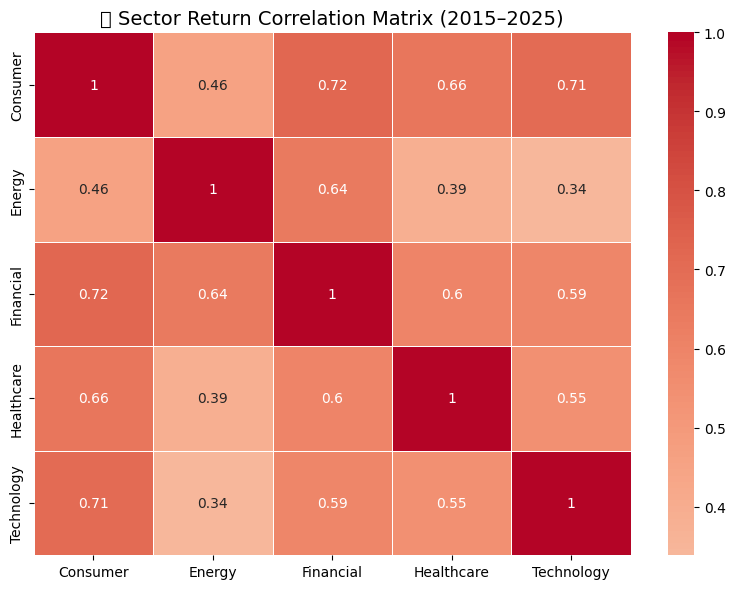

In [3]:
###Correlation 확인을 위한 Heatmap 생성###
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 섹터별 종목 지정
sectors = {
    'Consumer': ['AMZN', 'HD', 'MCD', 'NKE', 'SBUX', 'LOW', 'TGT', 'WMT', 'COST', 'DIS'],
    'Energy': ['XOM', 'CVX', 'COP', 'EOG', 'SLB', 'PSX', 'VLO', 'MPC', 'OXY', 'KMI'],
    'Financial': ['JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'AXP', 'BLK', 'SCHW', 'USB'],
    'Healthcare': ['JNJ', 'PFE', 'ABT', 'TMO', 'UNH', 'MRK', 'LLY', 'AMGN', 'GILD', 'BMY'],
    'Technology': ['AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'TSLA', 'NFLX', 'ADBE', 'CRM', 'INTC']
}

# 2. 가격 데이터 다운로드 (2015-06-01 ~ 2025-06-01)
start_date = "2015-06-01"
end_date = "2025-06-01"

price_data = {}
for sector, tickers in sectors.items():
    sector_df = yf.download(tickers, start=start_date, end=end_date)["Close"]
    price_data[sector] = sector_df.mean(axis=1)  # 섹터 평균가격

# 3. 섹터 수익률 계산
sector_returns = pd.DataFrame({sector: prices.pct_change() for sector, prices in price_data.items()}).dropna()

# 4. 상관계수 계산
corr_matrix = sector_returns.corr()

# 5. 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5, center=0)
plt.title("📈 Sector Return Correlation Matrix (2015–2025)", fontsize=14)
plt.tight_layout()
plt.show()


In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
from scipy.stats import norm, skew, kurtosis

# 유니버스 종목 리스트 (유니버스 제외 종목 제거: MCD, LOW, SBUX, PFE, BMY, SLB)
tickers = [
    'AMZN', 'HD', 'NKE', 'TGT', 'WMT', 'COST', 'DIS',
    'XOM', 'CVX', 'COP', 'EOG', 'PSX', 'VLO', 'MPC', 'OXY', 'KMI',
    'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'AXP', 'BLK', 'SCHW', 'USB',
    'JNJ', 'ABT', 'TMO', 'UNH', 'MRK', 'LLY', 'AMGN', 'GILD',
    'AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'TSLA', 'NFLX', 'ADBE', 'CRM', 'INTC'
]

# 1. 데이터 다운로드
start = '2015-06-01'
end = '2025-06-01'
price = yf.download(tickers, start=start, end=end)['Close']
returns = price.pct_change().dropna()

# 2. 위험지표 계산
risk_free_daily = 0.04 / 252
results = []

for ticker in tickers:
    ret = returns[ticker]
    cumulative = (1 + ret).cumprod()
    peak = cumulative.cummax()
    drawdown = (cumulative - peak) / peak
    max_dd = drawdown.min()

    ann_return = (1 + ret.mean())**252 - 1
    ann_vol = ret.std() * np.sqrt(252)

    # Historical VaR (5%) and CVaR
    var_hist = np.percentile(ret, 5)
    cvar_hist = ret[ret <= var_hist].mean()

    # Gaussian VaR
    var_gauss = norm.ppf(0.05, ret.mean(), ret.std())

    # Cornish-Fisher VaR
    z = norm.ppf(0.05)
    s = skew(ret)
    k = kurtosis(ret, fisher=True)
    z_cf = z + (1/6)*(z**2 - 1)*s + (1/24)*(z**3 - 3*z)*k
    cf_var = -(ret.mean() + z_cf * ret.std())

    results.append({
        'Ticker': ticker,
        'Annual Return': ann_return,
        'Annual Volatility': ann_vol,
        'Max Drawdown': max_dd,
        'VaR (Hist)': var_hist,
        'CVaR (Hist)': cvar_hist,
        'VaR (Gaussian)': var_gauss,
        'Cornish-Fisher VaR': cf_var,

    })

df = pd.DataFrame(results).set_index('Ticker')
df.sort_values(by='Annual Return', ascending=False)


/tmp/ipython-input-4-1884601391.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  price = yf.download(tickers, start=start, end=end)['Close']
[*********************100%***********************]  44 of 44 completed


,Annual Return,Annual Volatility,Max Drawdown,VaR (Hist),CVaR (Hist),VaR (Gaussian),Cornish-Fisher VaR
Ticker,,,,,,,
NVDA,0.967875,0.500980,-0.663351,-0.045407,-0.067424,-0.049220,0.039076
TSLA,0.610388,0.588985,-0.736322,-0.053814,-0.081158,-0.059136,0.052468
NFLX,0.427981,0.432502,-0.759473,-0.037488,-0.059914,-0.043399,0.038311
LLY,0.328402,0.291651,-0.252524,-0.025672,-0.039267,-0.029092,0.020408
META,0.328274,0.383667,-0.767361,-0.035593,-0.054295,-0.038627,0.030443
AMZN,0.322820,0.329381,-0.561453,-0.031629,-0.046956,-0.033018,0.029549
MSFT,0.322317,0.272194,-0.371485,-0.026582,-0.038576,-0.027094,0.023814
COST,0.272504,0.219717,-0.314024,-0.019930,-0.032108,-0.021810,0.020803
AAPL,0.266421,0.293921,-0.385159,-0.028404,-0.042518,-0.029517,0.026368


/tmp/ipython-input-5-1590955724.py:34: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


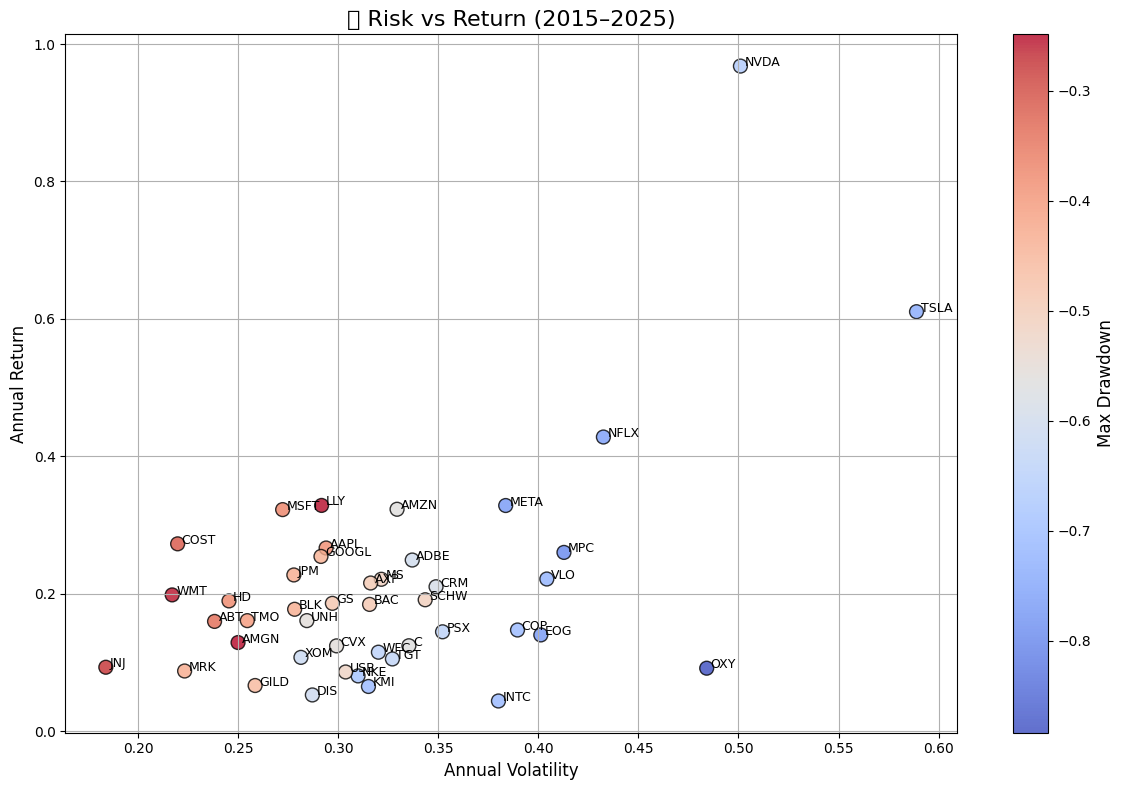

In [5]:
import matplotlib.pyplot as plt

# df: 과제 2번에서 만든 DataFrame (Annual Return, Annual Volatility, Max Drawdown, VaR 등 포함)
# 만약 df가 존재하지 않는다면 CSV로 불러오기
# df = pd.read_csv("results.csv", index_col='Ticker')

plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    df['Annual Volatility'],
    df['Annual Return'],
    c=df['Max Drawdown'],
    cmap='coolwarm',
    s=100,
    alpha=0.8,
    edgecolors='k'
)

# 라벨 추가
for ticker in df.index:
    plt.text(
        df.loc[ticker, 'Annual Volatility'] + 0.002,
        df.loc[ticker, 'Annual Return'],
        ticker,
        fontsize=9
    )

cbar = plt.colorbar(scatter)
cbar.set_label('Max Drawdown', fontsize=12)

plt.title('📈 Risk vs Return (2015–2025)', fontsize=16)
plt.xlabel('Annual Volatility', fontsize=12)
plt.ylabel('Annual Return', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()


/tmp/ipython-input-6-2708481603.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  price = yf.download(tickers, start=start, end=end)['Close']
[*********************100%***********************]  44 of 44 completed


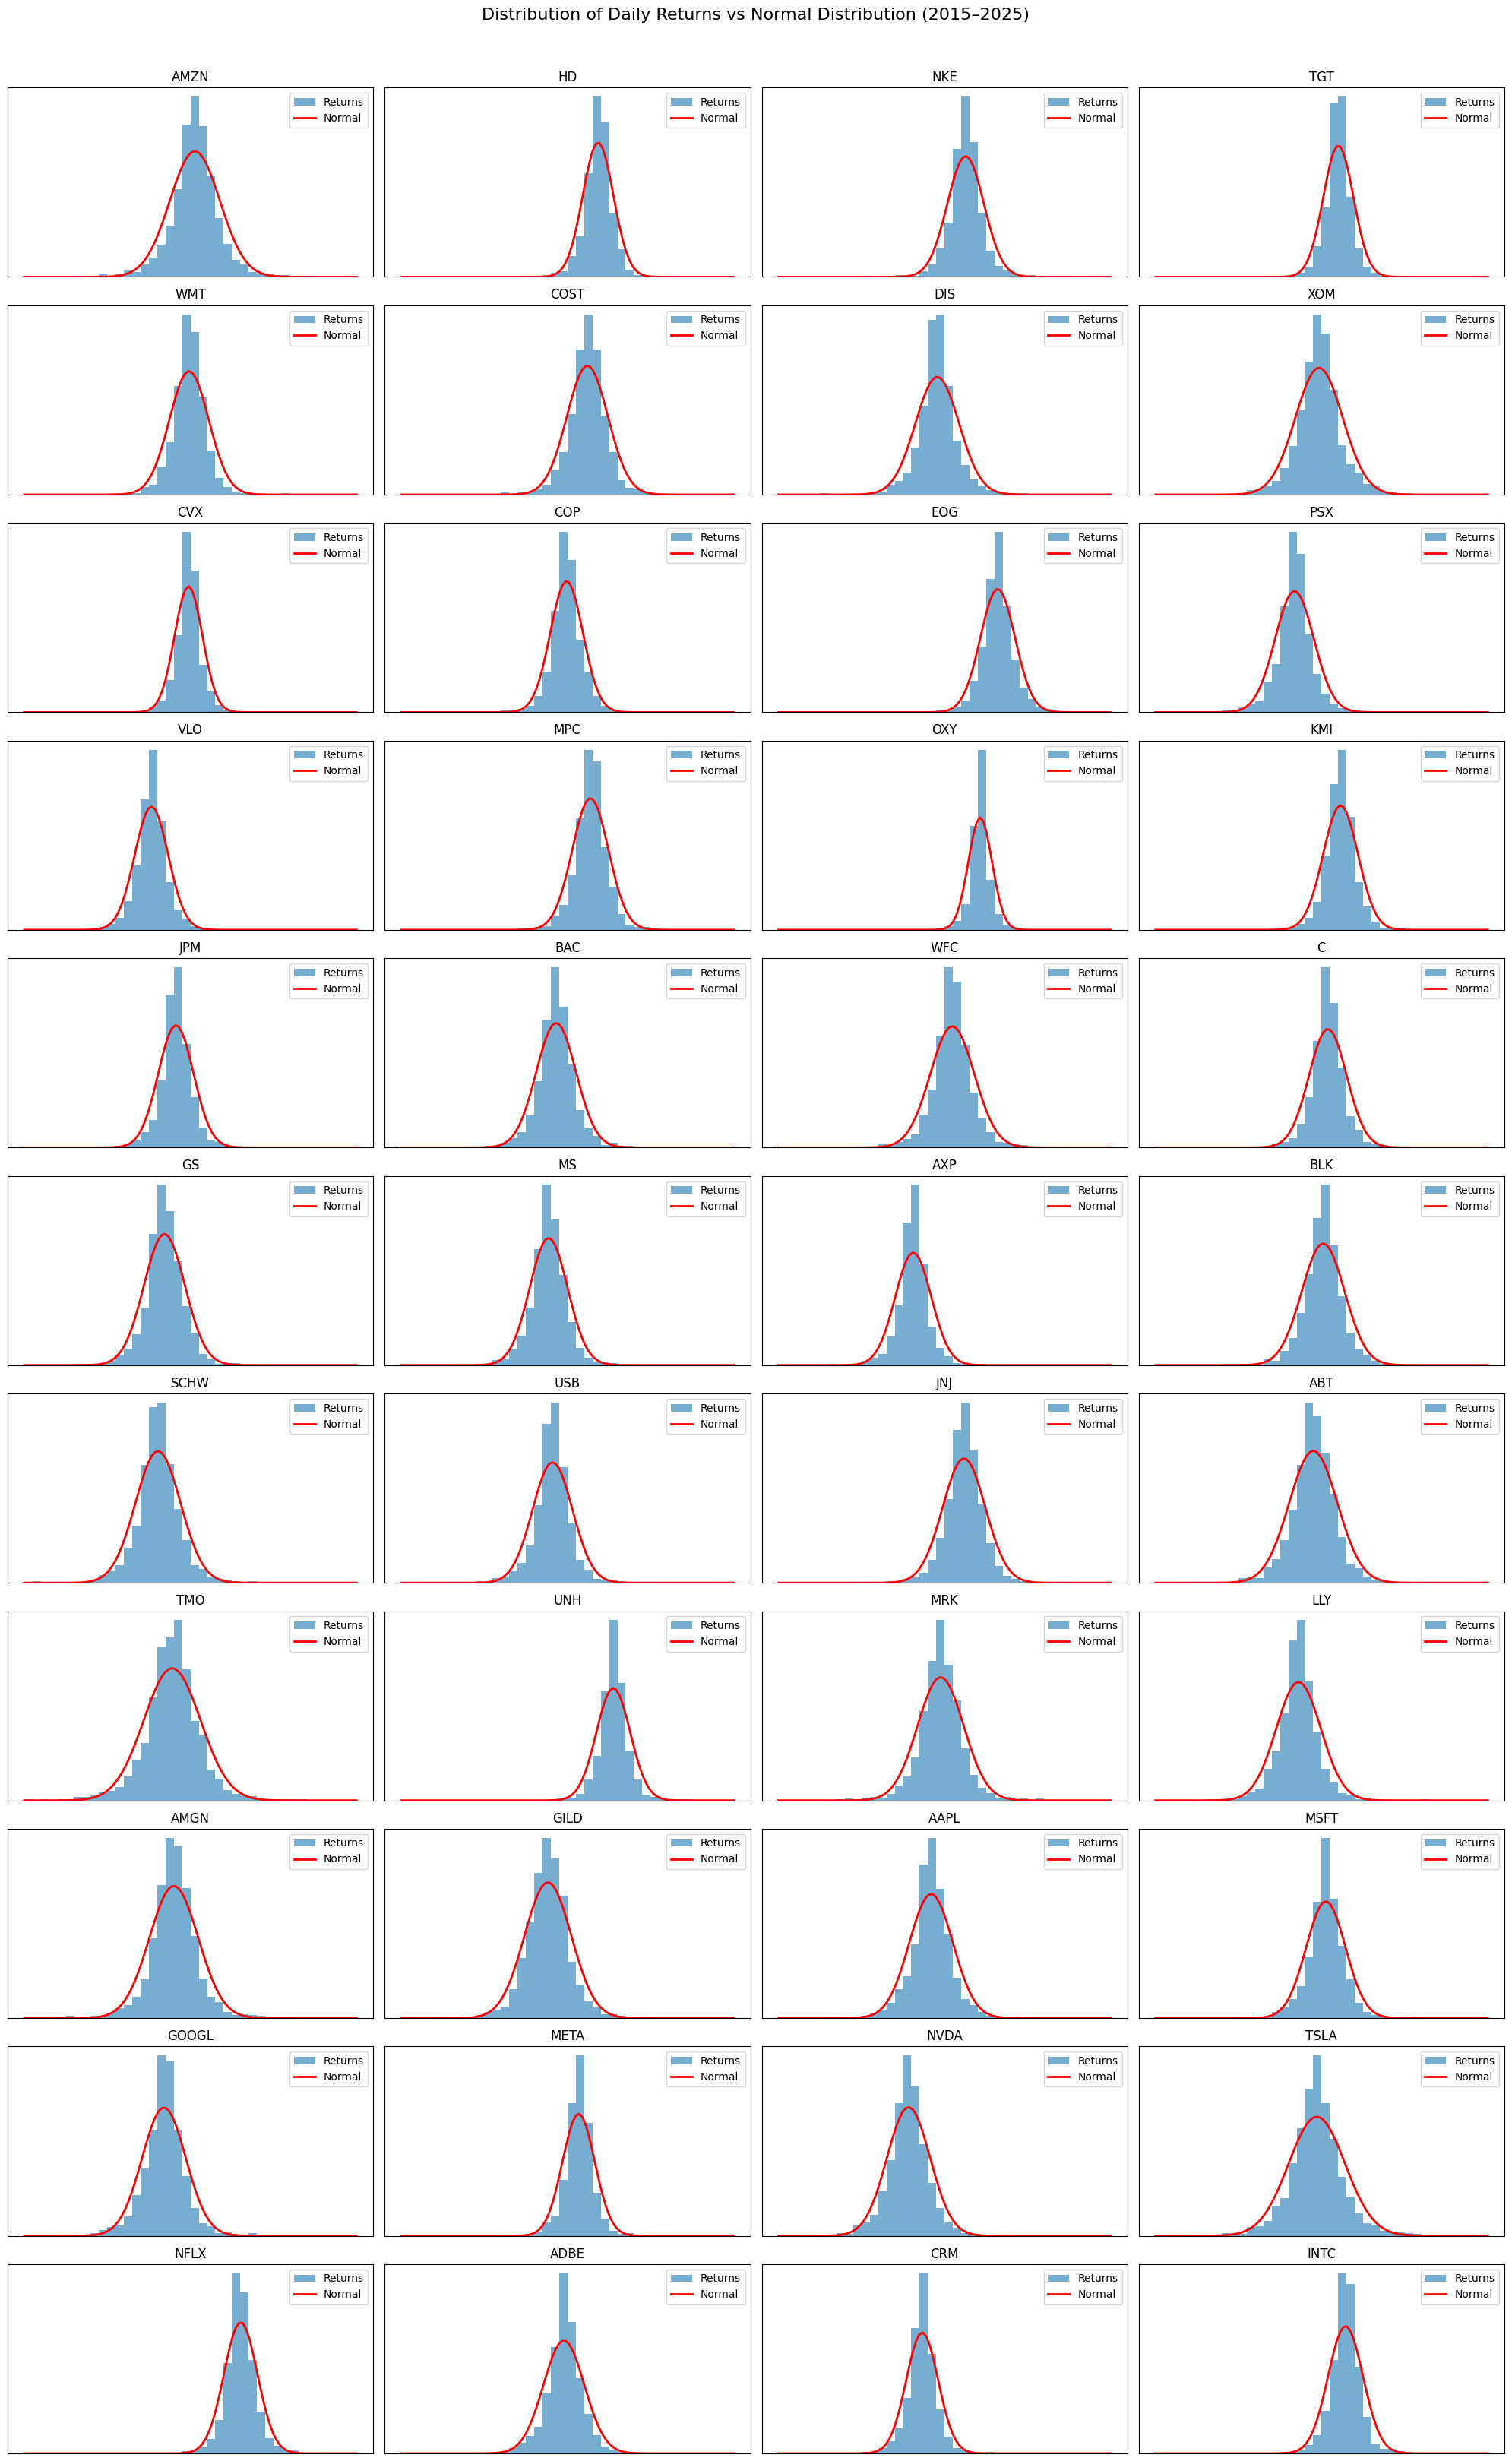

In [6]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

# 유니버스 종목 리스트 (제외 종목 제거)
tickers = [
    'AMZN', 'HD', 'NKE', 'TGT', 'WMT', 'COST', 'DIS',
    'XOM', 'CVX', 'COP', 'EOG', 'PSX', 'VLO', 'MPC', 'OXY', 'KMI',
    'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'AXP', 'BLK', 'SCHW', 'USB',
    'JNJ', 'ABT', 'TMO', 'UNH', 'MRK', 'LLY', 'AMGN', 'GILD',
    'AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'TSLA', 'NFLX', 'ADBE', 'CRM', 'INTC'
]

# 가격 데이터 수집
start = '2015-06-01'
end = '2025-06-01'
price = yf.download(tickers, start=start, end=end)['Close']
returns = price.pct_change().dropna()

# 시각화 설정
n_cols = 4
n_rows = int(np.ceil(len(tickers) / n_cols))
plt.figure(figsize=(20, 3 * n_rows))

for i, ticker in enumerate(tickers):
    r = returns[ticker]
    mu, sigma = r.mean(), r.std()
    x = np.linspace(r.min(), r.max(), 100)
    y = norm.pdf(x, mu, sigma)

    plt.subplot(n_rows, n_cols, i + 1)
    plt.hist(r, bins=40, density=True, alpha=0.6, label='Returns')
    plt.plot(x, y, 'r-', lw=2, label='Normal')
    plt.title(ticker)
    plt.xticks([])
    plt.yticks([])
    plt.legend()

plt.suptitle('Distribution of Daily Returns vs Normal Distribution (2015–2025)', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


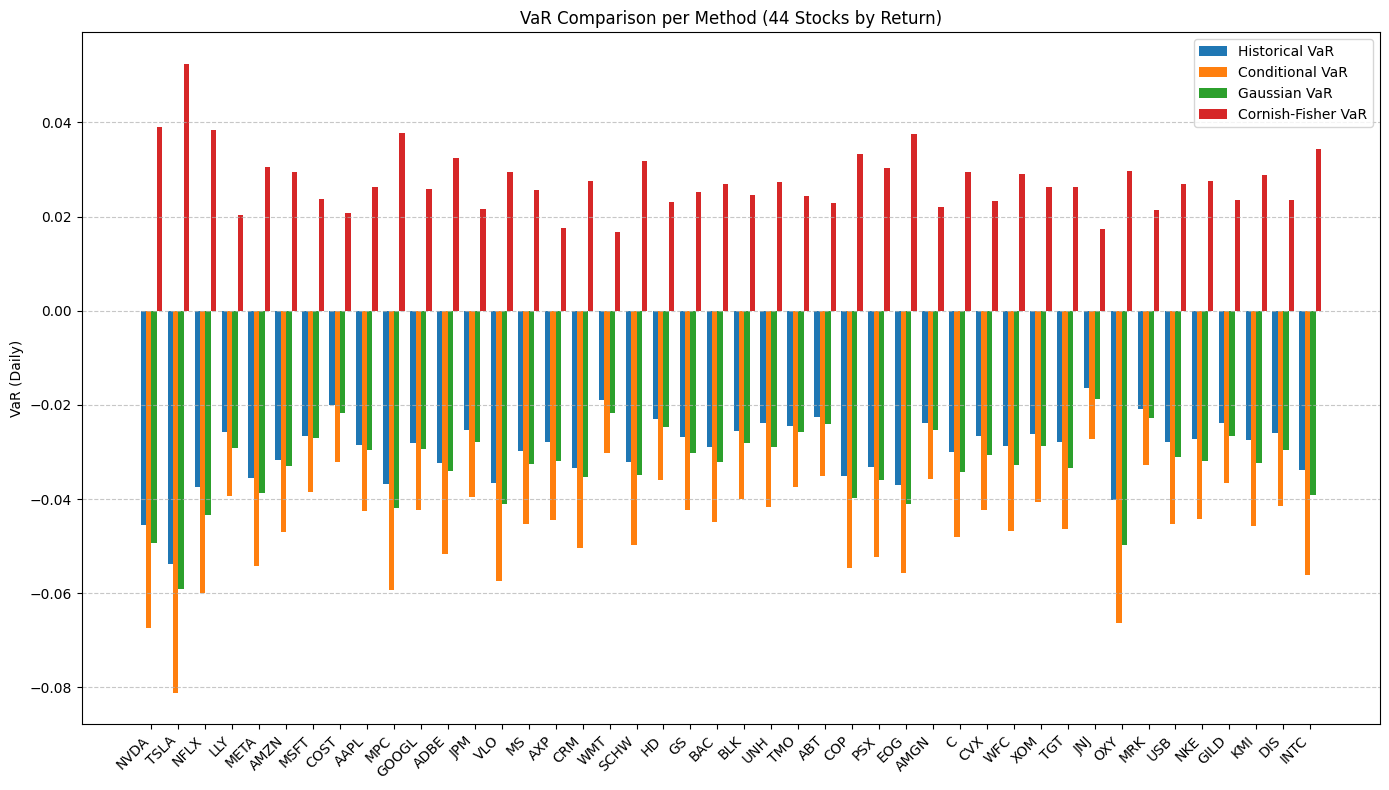

In [7]:
import matplotlib.pyplot as plt
import pandas as pd


df_sorted = df.sort_values(by='Annual Return', ascending=False).head(44)

# 시각화
plt.figure(figsize=(14, 8))
bar_width = 0.2
x = range(len(df_sorted))

plt.bar([i - 1.5 * bar_width for i in x], df_sorted['VaR (Hist)'], width=bar_width, label='Historical VaR')
plt.bar([i - 0.5 * bar_width for i in x], df_sorted['CVaR (Hist)'], width=bar_width, label='Conditional VaR')
plt.bar([i + 0.5 * bar_width for i in x], df_sorted['VaR (Gaussian)'], width=bar_width, label='Gaussian VaR')
plt.bar([i + 1.5 * bar_width for i in x], df_sorted['Cornish-Fisher VaR'], width=bar_width, label='Cornish-Fisher VaR')

plt.xticks(x, df_sorted.index, rotation=45, ha='right')
plt.ylabel('VaR (Daily)')
plt.title('VaR Comparison per Method (44 Stocks by Return)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [11]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 수익률 및 공분산행렬
returns = price.pct_change().dropna()
mean_returns = returns.mean() * 252
cov_matrix = returns.cov() * 252
tickers = mean_returns.index
rf = 0.04  # 연간 무위험 수익률

# 1. Sharpe Ratio 최대화 함수 정의
def negative_sharpe(weights):
    port_return = np.dot(weights, mean_returns)
    port_std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    sharpe = (port_return - rf) / port_std
    return -sharpe

# 2. Risk(Variance) 최소화 함수 정의
def portfolio_volatility(weights):
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

# 공통 제약조건 및 초기값
n = len(tickers)
constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0, 1) for _ in range(n))
init_guess = np.ones(n) / n

# 최적화 수행
opt_sharpe = minimize(negative_sharpe, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
opt_risk = minimize(portfolio_volatility, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)

# 결과 저장
weights_sharpe = pd.Series(opt_sharpe.x, index=tickers)
weights_risk = pd.Series(opt_risk.x, index=tickers)

# 요약 출력
print("📈 [Sharpe Max 포트폴리오]")
print(weights_sharpe[weights_sharpe > 0.01].round(4))

print("\n🛡️ [Risk Min 포트폴리오]")
print(weights_risk[weights_risk > 0.01].round(4))


📈 [Sharpe Max 포트폴리오]
Ticker
COST    0.1983
LLY     0.2876
NFLX    0.0228
NVDA    0.3331
TSLA    0.0524
WMT     0.1058
dtype: float64

🛡️ [Risk Min 포트폴리오]
Ticker
AMZN     0.0255
COST     0.1122
DIS      0.0452
GILD     0.0708
GOOGL    0.0148
JNJ      0.3071
KMI      0.0337
MRK      0.1208
UNH      0.0164
WMT      0.1852
XOM      0.0594
dtype: float64


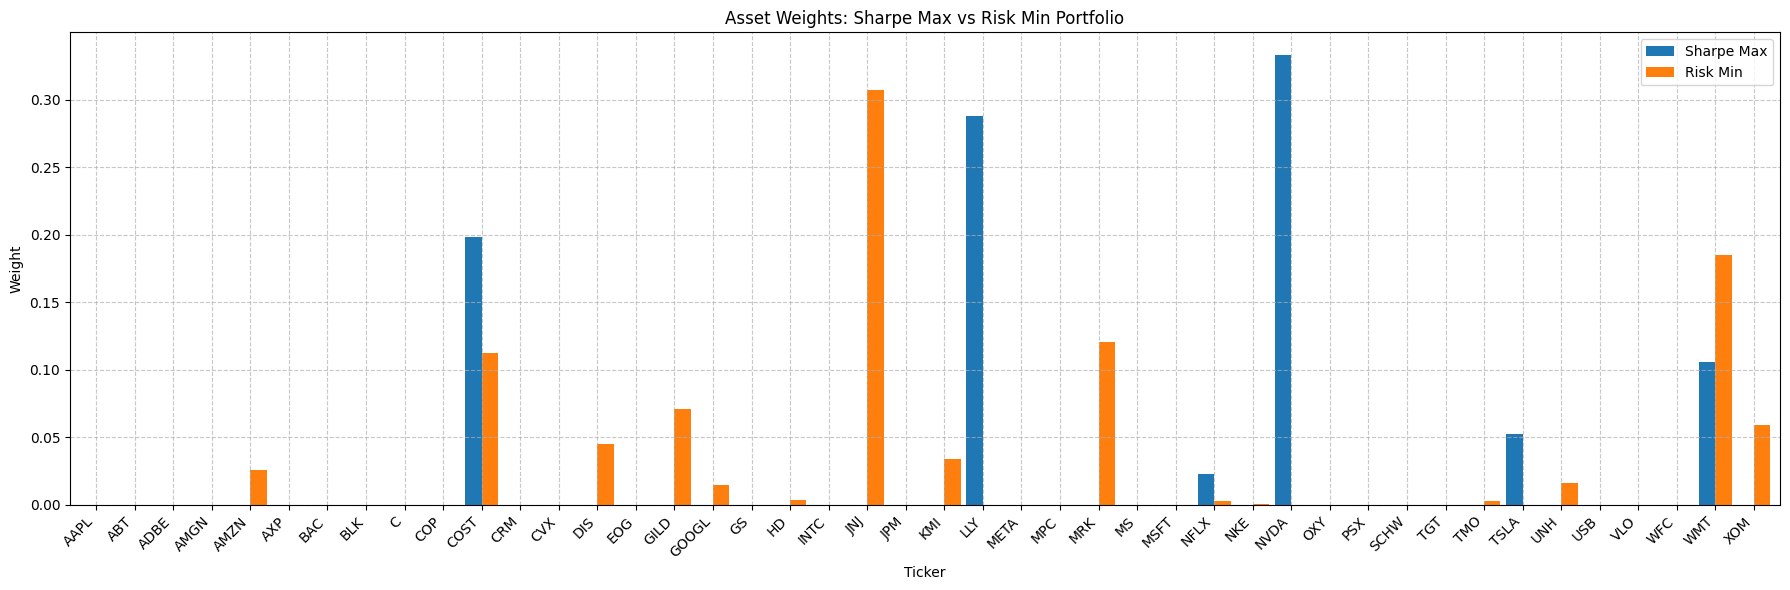

In [12]:
import matplotlib.pyplot as plt

# 가정: weights_sharpe, weights_risk는 모두 pd.Series (index=ticker)
df_weights = pd.DataFrame({
    'Sharpe Max': weights_sharpe,
    'Risk Min': weights_risk
})

# 시각화
df_weights.plot(kind='bar', figsize=(18, 6), width=0.85)
plt.title('Asset Weights: Sharpe Max vs Risk Min Portfolio')
plt.ylabel('Weight')
plt.xlabel('Ticker')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


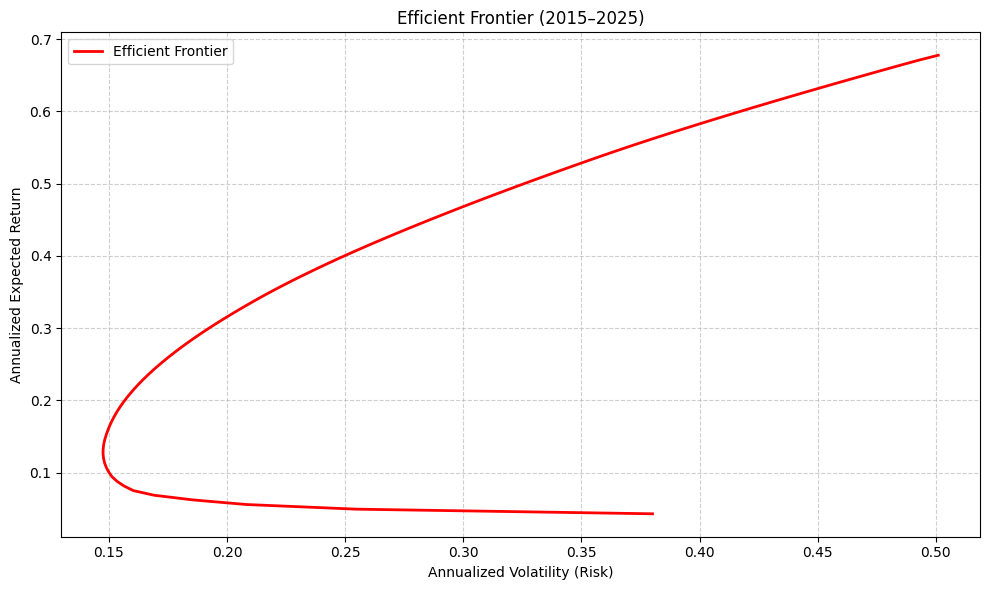

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 기본 데이터: 기대수익률, 공분산행렬, 종목 수
mu = mean_returns.values  # 기대수익률 벡터 (연율)
cov = cov_matrix.values   # 공분산 행렬 (연율)
tickers = mean_returns.index
n_assets = len(tickers)

# 경계 제약 조건
bounds = tuple((0, 1) for _ in range(n_assets))
constraints_sum = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}

# 목표 수익률 범위 설정 (선형 등간격)
target_returns = np.linspace(mu.min(), mu.max(), 100)
frontier_risks = []

for r_target in target_returns:
    constraints_return = {
        'type': 'eq',
        'fun': lambda w, mu=mu, r_target=r_target: np.dot(w, mu) - r_target
    }

    result = minimize(
        lambda w: np.dot(w.T, np.dot(cov, w)),  # 분산 최소화
        x0=np.ones(n_assets) / n_assets,
        bounds=bounds,
        constraints=[constraints_sum, constraints_return],
        method='SLSQP'
    )

    if result.success:
        risk = np.sqrt(np.dot(result.x.T, np.dot(cov, result.x)))
        frontier_risks.append(risk)
    else:
        frontier_risks.append(np.nan)

# 시각화
plt.figure(figsize=(10, 6))
plt.plot(frontier_risks, target_returns, label='Efficient Frontier', color='Red', lw=2)
plt.xlabel('Annualized Volatility (Risk)')
plt.ylabel('Annualized Expected Return')
plt.title('Efficient Frontier (2015–2025)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


/tmp/ipython-input-22-2221712265.py:24: FutureWarning: YF.download() has changed argument auto_adjust default to True
  price_data = yf.download(tickers, start=start_date, end=end_date)["Close"]
[*********************100%***********************]  44 of 44 completed
/tmp/ipython-input-22-2221712265.py:205: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


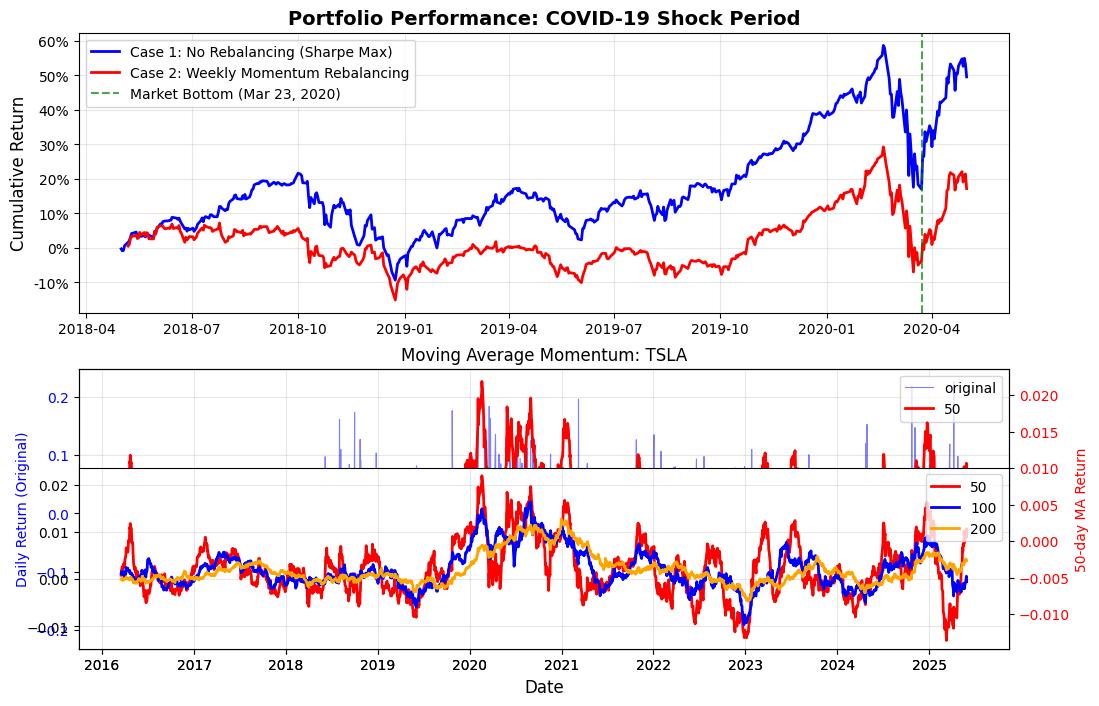

BACKTESTING RESULTS SUMMARY
Case 1 (No Rebalancing):
  - Final Return: 49.60%
  - Sharpe Ratio: 0.866

Case 2 (Weekly Momentum):
  - Final Return: 17.18%
  - Sharpe Ratio: 0.434

Debug Info:
Number of successful rebalancing weeks: 104
Total weekly periods: 104


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# 유니버스 종목 리스트
tickers = [
    'AMZN', 'HD', 'NKE', 'TGT', 'WMT', 'COST', 'DIS',
    'XOM', 'CVX', 'COP', 'EOG', 'PSX', 'VLO', 'MPC', 'OXY', 'KMI',
    'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'AXP', 'BLK', 'SCHW', 'USB',
    'JNJ', 'ABT', 'TMO', 'UNH', 'MRK', 'LLY', 'AMGN', 'GILD',
    'AAPL', 'MSFT', 'GOOGL', 'META', 'NVDA', 'TSLA', 'NFLX', 'ADBE', 'CRM', 'INTC'
]

# 데이터 수집 (모멘텀 계산을 위해 더 긴 기간)
start_date = "2015-06-01"  # 200일 이동평균을 위해
end_date = "2025-06-01"

# 백테스트 기간
backtest_start = "2018-05-01"
backtest_end = "2020-05-01"

# 데이터 다운로드
price_data = yf.download(tickers, start=start_date, end=end_date)["Close"]
returns = price_data.pct_change().dropna()

# Sharpe Max 포트폴리오 가중치
sharpe_weights_raw = {
    'AAPL': 0.0102, 'ABT': 0.0231, 'ADBE': 0.0094, 'AMGN': 0.0135, 'AMZN': 0.0179,
    'BAC': 0.0127, 'BLK': 0.0152, 'C': 0.0109, 'COP': 0.0098, 'COST': 0.1983,
    'CRM': 0.0061, 'CVX': 0.0116, 'DIS': 0.0087, 'EOG': 0.0101, 'GILD': 0.0105,
    'GOOGL': 0.0119, 'GS': 0.0104, 'HD': 0.0072, 'INTC': 0.0088, 'JNJ': 0.0173,
    'JPM': 0.0134, 'KMI': 0.0092, 'LLY': 0.2876, 'MRK': 0.0153, 'MS': 0.0123,
    'META': 0.0139, 'MPC': 0.0079, 'MSFT': 0.0177, 'NFLX': 0.0228, 'NKE': 0.0059,
    'NVDA': 0.3331, 'OXY': 0.0081, 'PSX': 0.0083, 'SCHW': 0.0111, 'TGT': 0.0077,
    'TMO': 0.0138, 'TSLA': 0.0524, 'UNH': 0.0113, 'USB': 0.0095, 'VLO': 0.0089,
    'WFC': 0.0107, 'WMT': 0.1058, 'XOM': 0.0122
}

# 가중치 정규화
available_tickers = list(returns.columns)
sharpe_weights = {}
for ticker in available_tickers:
    sharpe_weights[ticker] = sharpe_weights_raw.get(ticker, 0.0)

total_weight = sum(sharpe_weights.values())
if total_weight > 0:
    sharpe_weights = {k: v/total_weight for k, v in sharpe_weights.items()}

weights_series = pd.Series([sharpe_weights[ticker] for ticker in available_tickers],
                          index=available_tickers)

# Case 1: 리밸런싱 없음
backtest_returns = returns.loc[backtest_start:backtest_end]
portfolio_returns_case1 = backtest_returns.dot(weights_series)
cumulative_returns_case1 = (portfolio_returns_case1 + 1).cumprod()
final_return_case1 = cumulative_returns_case1.iloc[-1] - 1
sharpe_case1 = portfolio_returns_case1.mean() / portfolio_returns_case1.std() * np.sqrt(252)

# Case 2: 주간 모멘텀 리밸런싱
# 이동평균 모멘텀 계산
m50 = returns.rolling(50).mean()
m100 = returns.rolling(100).mean()
m200 = returns.rolling(200).mean()

# 주간 리밸런싱
weekly_dates = backtest_returns.resample('W-FRI').last().index
case2_returns_list = []

for i in range(1, len(weekly_dates)):
    week_start = weekly_dates[i-1]
    week_end = weekly_dates[i]

    # 해당 주의 거래일
    period_mask = (backtest_returns.index > week_start) & (backtest_returns.index <= week_end)
    period_returns = backtest_returns.loc[period_mask]

    if len(period_returns) == 0:
        continue

    # 모멘텀 스코어 계산 (m50, m100, m200의 평균)
    try:
        # week_start 날짜 또는 그 이전의 가장 가까운 날짜 찾기
        available_dates = m50.index[m50.index <= week_start]
        if len(available_dates) == 0:
            continue

        calc_date = available_dates[-1]

        momentum_50 = m50.loc[calc_date]
        momentum_100 = m100.loc[calc_date]
        momentum_200 = m200.loc[calc_date]

        # 종합 모멘텀 스코어 (각 모멘텀이 NaN이 아닌 경우만 평균에 포함)
        momentum_scores = pd.DataFrame({
            'm50': momentum_50,
            'm100': momentum_100,
            'm200': momentum_200
        })

        # 각 종목별로 사용 가능한 모멘텀의 평균 계산
        momentum_score = momentum_scores.mean(axis=1, skipna=True)
        momentum_score = momentum_score.dropna()

        if len(momentum_score) >= 10:
            # 상위 10개 종목 선택
            top_tickers = momentum_score.nlargest(10).index

            # 동일 가중치
            week_weights = pd.Series(0.0, index=available_tickers)
            for ticker in top_tickers:
                if ticker in week_weights.index:
                    week_weights[ticker] = 0.1

            # 해당 주의 포트폴리오 수익률
            portfolio_returns_period = period_returns.dot(week_weights)
            case2_returns_list.append(portfolio_returns_period)

    except Exception as e:
        print(f"Error in week {week_start} to {week_end}: {e}")
        continue

# Case 2 결과 계산
if len(case2_returns_list) > 0:
    case2_total = pd.concat(case2_returns_list).sort_index()
    cumulative_returns_case2 = (case2_total + 1).cumprod()
    final_return_case2 = cumulative_returns_case2.iloc[-1] - 1
    sharpe_case2 = case2_total.mean() / case2_total.std() * np.sqrt(252)
else:
    # 리밸런싱이 실패한 경우 Case 1과 동일하게 설정
    print("Warning: No successful rebalancing. Using Case 1 returns.")
    case2_total = portfolio_returns_case1.copy()
    cumulative_returns_case2 = cumulative_returns_case1.copy()
    final_return_case2 = final_return_case1
    sharpe_case2 = sharpe_case1

# 시각화
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# 첫 번째 subplot: 누적 수익률
axes[0].plot(cumulative_returns_case1.index, cumulative_returns_case1.values,
            label="Case 1: No Rebalancing (Sharpe Max)", linewidth=2, color='blue')
axes[0].plot(cumulative_returns_case2.index, cumulative_returns_case2.values,
            label="Case 2: Weekly Momentum Rebalancing", linewidth=2, color='red')
axes[0].axvline(pd.to_datetime("2020-03-23"), color='green', linestyle='--',
               label="Market Bottom (Mar 23, 2020)", alpha=0.7)
axes[0].set_title("Portfolio Performance: COVID-19 Shock Period", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Cumulative Return", fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y-1)))

# 두 번째 subplot: 샘플 종목의 모멘텀 (예시로 전체 기간 중 일부)
sample_ticker = 'TSLA' if 'TSLA' in available_tickers else available_tickers[0]

# 전체 기간에서 모멘텀 표시
full_returns = returns[sample_ticker]
full_m50 = m50[sample_ticker]
full_m100 = m100[sample_ticker]
full_m200 = m200[sample_ticker]

# 2009년 중반부터 2010년 말까지 유사한 기간 표시 (데이터가 있는 경우)
display_start = returns.index[200] if len(returns) > 200 else returns.index[0]
display_end = returns.index[-1]

mask = (returns.index >= display_start) & (returns.index <= display_end)

# 상단 그래프: 원본 수익률과 50일 이동평균 (이중 Y축 사용)
ax1_left = axes[1]
ax1_right = ax1_left.twinx()

# 왼쪽 Y축: 원본 수익률
ax1_left.plot(full_returns.loc[mask].index, full_returns.loc[mask],
              label='original', color='blue', alpha=0.5, linewidth=0.8)
ax1_left.set_ylabel("Daily Return (Original)", fontsize=10, color='blue')
ax1_left.tick_params(axis='y', labelcolor='blue')
ax1_left.grid(True, alpha=0.3)

# 오른쪽 Y축: 50일 이동평균
ax1_right.plot(full_m50.loc[mask].index, full_m50.loc[mask],
               label='50', color='red', linewidth=2)
ax1_right.set_ylabel("50-day MA Return", fontsize=10, color='red')
ax1_right.tick_params(axis='y', labelcolor='red')

# 범례 결합
lines1, labels1 = ax1_left.get_legend_handles_labels()
lines2, labels2 = ax1_right.get_legend_handles_labels()
ax1_left.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

axes[1].set_title(f'Moving Average Momentum: {sample_ticker}', fontsize=12)

# 하단 그래프: 50, 100, 200일 이동평균 비교를 위한 새로운 subplot
ax2 = fig.add_subplot(3, 1, 3, sharex=axes[1])
ax2.plot(full_m50.loc[mask].index, full_m50.loc[mask],
         label='50', color='red', linewidth=2)
ax2.plot(full_m100.loc[mask].index, full_m100.loc[mask],
         label='100', color='blue', linewidth=2)
ax2.plot(full_m200.loc[mask].index, full_m200.loc[mask],
         label='200', color='orange', linewidth=2)
ax2.legend(loc='upper right')
ax2.set_xlabel("Date", fontsize=12)
ax2.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

# 결과 출력
print("="*60)
print("BACKTESTING RESULTS SUMMARY")
print("="*60)
print(f"Case 1 (No Rebalancing):")
print(f"  - Final Return: {final_return_case1:.2%}")
print(f"  - Sharpe Ratio: {sharpe_case1:.3f}")
print(f"\nCase 2 (Weekly Momentum):")
print(f"  - Final Return: {final_return_case2:.2%}")
print(f"  - Sharpe Ratio: {sharpe_case2:.3f}")
print("="*60)

# 디버깅 정보
print(f"\nDebug Info:")
print(f"Number of successful rebalancing weeks: {len(case2_returns_list)}")
print(f"Total weekly periods: {len(weekly_dates)-1}")